In [ ]:
%matplotlib widget
import matplotlib.pyplot as plt
import pyrfu
from pyrfu import mms
from matplotlib import pyplot as plt
from pyrfu.plot import make_labels
from pyrfu.plot import plot_line, plot_spectr
import numpy as np
import xarray as xr
from pyrfu import pyrf
pyrfu.plot.set_color_cycle(pal = "pyrfu")

from copy import copy
from copy import deepcopy
import matplotlib
import pickle
mms.db_init(default="local", local="/data/mms")

Load IGRF coefficients ...


[10-Feb-26 16:36:27] INFO: Updating MMS data access configuration in /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/pyrfu/mms/config.json...
[10-Feb-26 16:36:27] INFO: Updating MMS SDC credentials in /homelocal/apostolosk/.config/python_keyring...


In [ ]:
print(np.__version__)
# !pip install --upgrade numpy

2.3.5


In [ ]:
with open("epoch_analysis_10b_84DFs.pickle", 'rb') as file:
    dict_ts_all = pickle.load(file)
# dict_ts_all = np.load("epoch_analysis_10b_84DFs.pickle", allow_pickle=True).item()
tints = [[str(dict_ts_all[it]["tint_new"][0]), str(dict_ts_all[it]["tint_new"][1])] for it in dict_ts_all.keys()]
t_df_tints = [dict_ts_all[it]["t_df_init"] for it in dict_ts_all.keys()]

tint2 = tints[49]
tint2 = pyrf.extend_tint(tint2, [0, -10])
tint1 = tints[57]
t_df2 = t_df_tints[49]
t_df1 = t_df_tints[57]

In [ ]:
# 3rd party imports
import numpy as np
from pyrfu.pyrf import (avg_4sc, norm, c_4_grad, dot, e_vxb,
                        dec_par_perp, sliding_derivative, resample, 
                        ts_convolve)
from pyrfu.mms import (get_data, rotate_tensor)
from scipy import constants

def w_err(tint, verbose = False, part_moments_en = 1e2, B_smooth_window = 1):
    r"""
    Function to calculate the betatron and Fermi acceleration terms, as well as the kappa parameter.
    
    Parameters:
    -----------
    tint : list of str
        Time interval.
    verbose : bool
        Verbose mode.
    part_moments_en : float
        Lowest included energy for particle moments.
    kappa_limit : float
        Limit for kappa parameter.
    B_smooth_window : float
        Window size for smoothing the magnetic field.
    
    Returns:
    --------
    W_betatron : xarray.DataArray
        Betatron acceleration term.
    W_fermi : xarray.DataArray
        Fermi acceleration term.
    w_betatron : xarray.DataArray
        Betatron acceleration term normalized by the electron density.
    w_fermi : xarray.DataArray
        Fermi acceleration term normalized by the electron density.
    kappa_roll : xarray.DataArray
        Kappa parameter.
    """

    ### Load data
    Egse_fast = [get_data(f"e_gse_edp_brst_l2", tint=tint, mms_id=id, verbose = verbose) for id in range(1, 5)]
    Bgse = [get_data(f'b_gse_fgm_brst_l2', tint=tint, mms_id=id, verbose = verbose) for id in range(1, 5)]
    
    Ve_gse_part = [get_data(f'partve_gse_fpi_brst_l2', tint=tint, mms_id=id, verbose = verbose) for id in range(1, 5)]
    
    idx_energy_cut = [np.where(Ve_gse_part[i].lowest_included_energy > part_moments_en)[0][0] for i in range(4)]
    Ve_gse = [Ve_gse_part[i][:, idx_energy_cut[i], :] for i in range(4)]

    n_e_part = [get_data(f"partne_fpi_brst_l2", tint, id, verbose = verbose) for id in range(1, 5)]
    
    idx_energy_cut = [np.where(n_e_part[i].lowest_included_energy > part_moments_en)[0][0] for i in range(4)]
    n_e = [n_e_part[i][:, idx_energy_cut[i]] for i in range(4)]

    partt_perp_e = [get_data(f"parttperpe_fpi_brst_l2", tint, id, verbose = verbose) for id in range(1, 5)]
    idx_energy_cut = [np.where(partt_perp_e[i].lowest_included_energy > part_moments_en)[0][0] for i in range(4)]
    t_perp_e = [partt_perp_e[i][:, idx_energy_cut[i]] for i in range(4)]
    
    partt_para_e = [get_data(f"parttparae_fpi_brst_l2", tint, id, verbose = verbose) for id in range(1, 5)]
    idx_energy_cut = [np.where(partt_para_e[i].lowest_included_energy > part_moments_en)[0][0] for i in range(4)]

    r_gse = [get_data(f'r_gse_mec_srvy_l2', tint, mms_id, verbose = verbose) for mms_id in range(1,5)]
    for i in range(len(r_gse)):
        r_gse[i].coords["comp"] = np.array(["x", "y", "z"])
    
    t_perp_e_smoothed = [resample(t_perp_e[i], n_e[i]) for i in range(4)]

    pe_part = [get_data(f'pe_gse_fpi_brst_l2', tint=tint, mms_id=id, verbose = verbose) for id in range(1, 5)]

    pe_cut = pe_part
    pe_cut_fac = [rotate_tensor(pe_cut[i], "fac", Bgse[i], "pp") for i in range(4)]
    
    pe_cut_perp = [(pe_cut_fac[i][:,1,1]) for i in range(4)]

    ### Calculate acceleration terms
    n_e_avg = avg_4sc(n_e)
    E_gse_fast = [resample(Egse_fast[i], n_e[i]) for i in range(4)]
    Bgse_smoothed = [resample(Bgse[i], n_e[i]) for i in range(4)]
    Bgse_smoothed = [ts_convolve(Bgse_smoothed[i], np.ones(shape = B_smooth_window)/B_smooth_window) for i in range(4)]
    
        ### Calculate betatron acceleration
    B_mag = [norm(Bgse_smoothed[i]) for i in range(4)]
    r_gse = [resample(r_gse[i], B_mag[i]) for i in range(4)]
    gradB = c_4_grad(r_gse, B_mag)

    u_E = [e_vxb(E_gse_fast[i], Bgse_smoothed[i], flag = "exb") for i in range(4)]
    
    db_dt_5ps = avg_4sc([sliding_derivative(B_mag[i],  t_units= "ns",method = "5ps") for i in range(4)])

    pe_perp_avg = avg_4sc(pe_cut_perp)

    u_E_avg = resample(avg_4sc(u_E), n_e_avg)
    uE_dot_gradB_avg = dot(u_E_avg, gradB)

    B_mag_avg = avg_4sc(B_mag)
    gradB = resample(c_4_grad(r_gse, B_mag, method = "grad"), n_e_avg)

    ev2j = constants.physical_constants["electron volt-joule relationship"][0]
    
    Ve_para = [dec_par_perp(Ve_gse[i], Bgse[i])[0] for i in range(4)]
    pe_cut_para = [(pe_cut_fac[i][:,0,0]) for i in range(4)]
    curv = resample(c_4_grad(r_gse, Bgse_smoothed,  method = "curv"), n_e_avg)

    pe_para_avg = resample(avg_4sc(pe_cut_para), n_e_avg)
    
    Ve_para_avg = resample(avg_4sc(Ve_para), n_e_avg)

    pe_err = [mms.get_data(f'errpe_fpi_brst_l2', tint=tint, mms_id=id, verbose=False) for id in range(1, 5)]
    
    pe_err_fac = [mms.rotate_tensor(pe_err[i], "fac", Bgse[i], "pp") for i in range(4)]

    B_avg = avg_4sc(Bgse_smoothed)

    pe_err_perp = [(pe_err_fac[i][:,1,1]) for i in range(4)]
    pe_err_para = [(pe_err_fac[i][:,0,0]) for i in range(4)]

    pe_perp_dpeerr_perp = [pe_cut_perp[i] + pe_err_perp[i] for i in range(4)]
    pe_perp_avg_plus_err = avg_4sc(pe_perp_dpeerr_perp)

    b = avg_4sc([Bgse_smoothed[i] / pyrf.norm(Bgse_smoothed[i]) for i in range(4)])

    E_fac = [pyrf.dec_par_perp(E_gse_fast[i], Bgse_smoothed[i]) for i in range(4)]
    E_perp = [E_fac[i][1] for i in range(4)]

    E_err = [mms.get_data(f'erre_edp_fast_l2', tint=tint, mms_id=id, verbose=False) for id in range(1, 5)]
    E_err_fac = [pyrf.dec_par_perp(E_err[i], Bgse_smoothed[i]) for i in range(4)]
    Eperp_err = [E_err_fac[i][1] for i in range(4)]
    
    Eperp_plus_Eperperr = [resample(E_perp[i], Eperp_err[i]) + Eperp_err[i] for i in range(4)]
    E_perp_avg_plus_err = avg_4sc(Eperp_plus_Eperperr)

    
    d_gradB = np.ones_like(gradB)
    d_gradB = xr.DataArray(d_gradB, coords=gradB.coords, dims=gradB.dims)

    W_betatron = resample(pe_perp_avg, n_e_avg) * (resample(db_dt_5ps, n_e_avg) + uE_dot_gradB_avg)/resample(B_mag_avg, n_e_avg) *6.24151

    w_betatron = W_betatron / n_e_avg

    d_Wb = pe_perp_avg_plus_err / avg_4sc(B_mag)**2 * dot(pyrf.cross(b, gradB + d_gradB) , E_perp_avg_plus_err) * 6.24151

    d_ne = [mms.get_data(f'errne_fpi_brst_l2', tint=tint, mms_id=id, verbose=False) for id in range(1, 5)]

    ve_err = [mms.get_data(f'errve_fpi_brst_l2', tint=tint, mms_id=id, verbose=False) for id in range(1, 5)]

    ve_err_par = [pyrf.dec_par_perp(ve_err[i], Bgse_smoothed[i])[0] for i in range(4)]
    
    pe_para_prime = [1e-15*pe_cut_para[i] + 1e6 * constants.m_e * n_e[i] * (Ve_para[i])**2 for i in range(4)]

    d_pe_para_prime = [1e-15*pe_err_para[i] + 1e6 * constants.m_e * np.sqrt((d_ne[i]/n_e[i])**2 + 4*(ve_err_par[i]/Ve_para[i])**2) * n_e[i] * (Ve_para[i])**2 for i in range(4)]


    pe_para_prime_d_pe_para_prime = [pe_para_prime[i] + d_pe_para_prime[i] for i in range(4)]
    pe_para_prime_avg_plus_err = avg_4sc(pe_para_prime_d_pe_para_prime)
    
    W_fermi = 1e-3 * ev2j**(-1) * (1e-15*pe_para_avg + 1e6 * constants.m_e * n_e_avg * (Ve_para_avg)**2) \
                * dot(u_E_avg, curv )
    
    w_fermi = W_fermi / n_e_avg

    d_Wf = 1e-3*ev2j**(-1) * pe_para_prime_avg_plus_err / avg_4sc(B_mag)**2 * dot(pyrf.cross(B_avg, curv + dot(B_avg, d_gradB)/avg_4sc(B_mag)**2 ), E_perp_avg_plus_err)

    d_wb = w_betatron * np.sqrt(d_Wb**2/W_betatron**2 + avg_4sc(d_ne)**2/n_e_avg**2)
    d_wf = w_fermi * np.sqrt(d_Wf**2/W_fermi**2 + avg_4sc(d_ne)**2/n_e_avg**2)

    Rc = resample(norm(c_4_grad(r_gse, Bgse_smoothed,  method = "curv"))**(-1), avg_4sc(t_perp_e_smoothed))
    Rc_roll = Rc.rolling(time = 15, center=True).median()

    Rg = [1e-3*np.sqrt(2*t_perp_e_smoothed[i] * ev2j/constants.electron_mass) * 
          constants.electron_mass/
          (constants.e * resample(B_mag[i], n_e[i])*1e-9) 
          for i in range(4)]
    
    Rg_avg = avg_4sc(Rg)
    
    kappa_roll = np.sqrt(Rc_roll/Rg_avg)
    ### Calculate kappa for extra energy
    extra_energy = 10e4 #eV

    Rg_extra_energy = [1e-3 * constants.electron_mass/(constants.e * resample(B_mag[i], n_e[i]) * 1e-9) 
                   * np.sqrt(2 * extra_energy * ev2j / constants.electron_mass)
                    for i in range(4)]
    Rg_extra_energy_avg = avg_4sc(Rg_extra_energy)
    
    kappa_extra_energy = np.sqrt(Rc_roll / Rg_extra_energy_avg)


    return W_betatron, W_fermi, d_Wb, d_Wf, w_betatron, w_fermi, d_wb, d_wf, kappa_roll, kappa_extra_energy


In [ ]:
W_betatron1, W_fermi1, dW_betatron1, dW_fermi1, w_betatron1, w_fermi1, dw_betatron1, dw_fermi1, kappa_roll1, kappa_extra_energy1 = w_err(tint = tint1, verbose = False, part_moments_en=1e2, B_smooth_window=11)
W_betatron2, W_fermi2, dW_betatron2, dW_fermi2, w_betatron2, w_fermi2, dw_betatron2, dw_fermi2, kappa_roll2, kappa_extra_energy2 = w_err(tint = tint2, verbose = False, part_moments_en=1e2, B_smooth_window=11)


In [ ]:
part_moments_en = 1e2

In [ ]:
def load_data(tint, part_moments_en):

    Bgse = [mms.get_data(f'b_gsm_fgm_brst_l2', tint=tint, mms_id=id,verbose=False) for id in range(1, 5)]
    Bgse_avg = pyrf.avg_4sc(Bgse)

    b_dmpa = [mms.get_data("b_dmpa_fgm_brst_l2", tint = tint, mms_id = id, verbose=False) for id in range(1, 5)]
    # Vigse = [mms.get_data(f'vi_gse_fpi_{sampl2}_l2', tint=tint, mms_id=id, ) for id in range(1, 5)]

    Vi_gse_part = [mms.get_data(f'partvi_gse_fpi_brst_l2', tint=tint, mms_id=id, verbose=False) for id in range(1, 5)]

    idx_energy_cut = [np.where(Vi_gse_part[i].lowest_included_energy > part_moments_en)[0][0] for i in range(4)]
    Vigse = [Vi_gse_part[i][:, idx_energy_cut[i], :] for i in range(4)]
    Vigse = [pyrf.cotrans(Vigse[i], "gse>gsm", ) for i in range(4)]
    Vi_avg = pyrf.avg_4sc(Vigse)

    Vi_hpca = [mms.get_data(f"vhplus_dbcs_hpca_srvy_l2", tint, mms_id, verbose = False) for mms_id in range(1, 5)]
    ancillary = [mms.load_ancillary(product = "defatt", tint = tint, mms_id = mms_id, verbose = False) for mms_id in range(1, 5)]
    Vi_hpca = [mms.dsl2gse(Vi_hpca[i], ancillary[i], direction = +1) for i in range(len(Vi_hpca))]
    Vi_hpca = [pyrf.cotrans(Vi_hpca[i], "gse>gsm", ) for i in range(4)]
    Vi_avg_hpca = pyrf.avg_4sc(Vi_hpca)

    Egse_fast = [mms.get_data(f'e_gse_edp_fast_l2', tint=tint, mms_id=id, verbose=False) for id in range(1, 5)]
    Bgsm_fast = [mms.get_data(f'b_gsm_fgm_srvy_l2', tint=tint, mms_id=id, verbose=False) for id in range(1, 5)]
    Egsm_fast = [pyrf.cotrans(Egse_fast[i], "gse>gsm", ) for i in range(4)]
    u_E = [pyrf.e_vxb(Egsm_fast[i], Bgsm_fast[i], flag = "exb") for i in range(4)]
    u_E_avg = pyrf.avg_4sc(u_E)

    vdf_e = [];
    for id in range(4):
        vdf = mms.get_data(f"pde_fpi_brst_l2", tint, id+1, verbose=False)
        vdf_e.append(vdf)

    vdf_e = [mms.psd2def(vdf) for vdf in vdf_e]

    def_omni_e = [];
    for id in range(4):
        def_omni = mms.get_data(f"defe_fpi_brst_l2", tint, id+1, verbose=False)
        def_omni_e.append(def_omni)

    pad_def_e = [mms.get_pitch_angle_dist(vdf_e[i], b_dmpa[i], tint=tint, angles = 11) for i in range(4)]

    n_i_part = []; n_e_part = []; 
    for id in range(4):
            
        n_part = [mms.get_data(f"partn{s}_fpi_brst_l2", tint, id+1, verbose=False) for s in ["e"]]
        # n_i_part.append(n_part[0]); 
        n_e_part.append(n_part[0])
        
    idx_energy_cut = [np.where(n_e_part[i].lowest_included_energy > part_moments_en)[0][0] for i in range(4)]
    n_e = [n_e_part[i][:, idx_energy_cut[i]] for i in range(4)]
    n_e_avg = pyrf.avg_4sc(n_e)

    # idx_energy_cut = [np.where(n_i_part[i].lowest_included_energy > part_moments_en)[0][0] for i in range(4)]
    # n_i = [n_i_part[i][:, idx_energy_cut[i]] for i in range(4)]
    # n_i_avg = pyrf.avg_4sc(n_i)

    partt_perp_e = [mms.get_data(f"parttperpe_fpi_brst_l2", tint, id, verbose=False) for id in range(1, 5)]
    idx_energy_cut = [np.where(partt_perp_e[i].lowest_included_energy > part_moments_en)[0][0] for i in range(4)]
    t_perp_e = [partt_perp_e[i][:, idx_energy_cut[i]] for i in range(4)]
    t_perp_e_avg = pyrf.avg_4sc(t_perp_e)

    partt_para_e = [mms.get_data(f"parttparae_fpi_brst_l2", tint, id, verbose=False) for id in range(1, 5)]
    idx_energy_cut = [np.where(partt_para_e[i].lowest_included_energy > part_moments_en)[0][0] for i in range(4)]
    t_para_e = [partt_para_e[i][:, idx_energy_cut[i]] for i in range(4)]
    t_para_e_avg = pyrf.avg_4sc(t_para_e)

    return Bgse_avg, Vi_avg, Vi_avg_hpca, n_e_avg, t_perp_e_avg, t_para_e_avg, pad_def_e, def_omni_e, vdf_e, u_E_avg

Bgse_avg1, Vi_avg1, Vi_avg_hpca1, n_e_avg1, t_perp_e_avg1, t_para_e_avg1, pad_def_e1, def_omni_e1, vdf_e1, u_E_avg1 = load_data(tint1, part_moments_en)
Bgse_avg2, Vi_avg2, Vi_avg_hpca2, n_e_avg2, t_perp_e_avg2, t_para_e_avg2, pad_def_e2, def_omni_e2, vdf_e2, u_E_avg2 = load_data(tint2, part_moments_en)

[10-Feb-26 16:37:07] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/pandas/core/generic.py:3322: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  return xarray.Dataset.from_dataframe(self)

[10-Feb-26 16:37:07] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/pandas/core/generic.py:3322: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. Thi

In [ ]:
energy_ranges_feeps=[[32.1, 50], [50, 100], [102, 130]]

In [ ]:
psd_vdf_e1 = [mms.def2psd(vdf_e1[i]) for i in range(4)]
dpf_vdf_e1 = [mms.psd2dpf(psd_vdf_e1[i]) for i in range(4)]

psd_vdf_e2 = [mms.def2psd(vdf_e2[i]) for i in range(4)]
dpf_vdf_e2 = [mms.psd2dpf(psd_vdf_e2[i]) for i in range(4)]

In [ ]:
dpf_fpi_omni_e1 = [mms.vdf_omni(dpf_vdf_e1[i]) for i in range(4)]
dpf_fpi_omni_e2 = [mms.vdf_omni(dpf_vdf_e2[i]) for i in range(4)]

dpf_fpi_omni_e_avg1 = pyrf.nanavg_4sc(dpf_fpi_omni_e1)
dpf_fpi_omni_e_avg2 = pyrf.nanavg_4sc(dpf_fpi_omni_e2)

In [ ]:
fpi_energy_channels = [24]
fpi_en_channel_id_start = 10
def split_energy(pad, idx, id_start):
        
        coords = [pad.time.data, pad.theta.data[0, :]]
        dims = ["time", "theta"]
        attrs = pad.attrs
        energy = pad.energy.data[0, :]
        idx.insert(0, id_start)
        idx.append(-1)
     
        pad_dE = []
        
        for i_dE in range(len(idx) - 1):
            
            pad_dE.append([xr.DataArray(np.nanmean(pad.data[:,idx[i_dE]: idx[i_dE + 1], :], axis=1), coords=coords, dims=dims, attrs = attrs), 
                           "{:2.1f} - {:2.1f} keV".format(energy[idx[i_dE]]*1e-3, energy[idx[i_dE+1]]*1e-3)])

        return pad_dE
    
pad_def_e_ch_splits = []

pad_def_e_ch_splits1 = []
pad_def_e_ch_splits2 = []

for id in range(4):

    pad_def_e_ch_splits1.append(split_energy(pad_def_e1[id], idx = copy(fpi_energy_channels), id_start = fpi_en_channel_id_start))
    pad_def_e_ch_splits2.append(split_energy(pad_def_e2[id], idx = copy(fpi_energy_channels), id_start = fpi_en_channel_id_start))

def_fpi_pad_e_ch_splits_4sc1 = [[pyrf.avg_4sc([pad_def_e_ch_splits1[i_sc][i_en][0] for i_sc in range(4)])] for i_en in range(len(fpi_energy_channels)+1)]
def_fpi_pad_e_ch_splits_4sc2 = [[pyrf.avg_4sc([pad_def_e_ch_splits2[i_sc][i_en][0] for i_sc in range(4)])] for i_en in range(len(fpi_energy_channels)+1)]

for i in range(len(def_fpi_pad_e_ch_splits_4sc1)):
    if len(def_fpi_pad_e_ch_splits_4sc1[i]) < 2:
        def_fpi_pad_e_ch_splits_4sc1[i].append(pad_def_e_ch_splits1[0][i][-1])

for i in range(len(def_fpi_pad_e_ch_splits_4sc2)):
    if len(def_fpi_pad_e_ch_splits_4sc2[i]) < 2:
        def_fpi_pad_e_ch_splits_4sc2[i].append(pad_def_e_ch_splits2[0][i][-1])

In [ ]:
dpf_feeps_alle_e1 = [mms.get_feeps_alleyes(f"fluxe_brst_l2", tint1, mms_id, verbose=False) for mms_id in range(1, 5)]
dpf_feeps_e_corr1 = [mms.feeps_corrections(deepcopy(dpf_feeps_alle_e1[i])) for i in range(4)]
dpf_feeps_e_corr1 = [mms.feeps_remove_sunlit_sectors(dpf_feeps_e_corr1[i], outliers_q=0.99) for i in range(4)]
dpf_feeps_omni_e1 = [mms.feeps_omni(dpf_feeps_e_corr1[i],) for i in range(4)]

dpf_feeps_alle_e2 = [mms.get_feeps_alleyes(f"fluxe_brst_l2", tint2, mms_id, verbose=False) for mms_id in range(1, 5)]
dpf_feeps_e_corr2 = [mms.feeps_corrections(deepcopy(dpf_feeps_alle_e2[i])) for i in range(4)]
dpf_feeps_e_corr2 = [mms.feeps_remove_sunlit_sectors(dpf_feeps_e_corr2[i], outliers_q=0.99) for i in range(4)]
dpf_feeps_omni_e2 = [mms.feeps_omni(dpf_feeps_e_corr2[i],) for i in range(4)]

In [ ]:
b_bcs1 = [mms.get_data("b_bcs_fgm_brst_l2", tint1, mms_id) for mms_id in range(1, 5)]
b_bcs2 = [mms.get_data("b_bcs_fgm_brst_l2", tint2, mms_id) for mms_id in range(1, 5)]

n_pabins = 11
bin_size = 180.0 / n_pabins
energy_ranges = [[32.1, 100]]

dpf_feeps_pad_e_energy_ranges1 = []
dpf_feeps_pad_e_energy_ranges2 = []

for i in range(4):
    dpf_feeps_pad_e_energy_ranges1.append([mms.feeps_pad(dpf_feeps_e_corr1[i], b_bcs1[i], energy = energy_range, bin_size=bin_size) for energy_range in energy_ranges])
    dpf_feeps_pad_e_energy_ranges2.append([mms.feeps_pad(dpf_feeps_e_corr2[i], b_bcs2[i], energy = energy_range, bin_size=bin_size) for energy_range in energy_ranges])

dpf_feeps_pad_4sc_enranges1 = [mms.feeps_avg_4sc([dpf_feeps_pad_e_energy_ranges1[i_sc][i_en] for i_sc in range(4)], flag="pad") for i_en in range(len(energy_ranges))]
dpf_feeps_pad_4sc_enranges2 = [mms.feeps_avg_4sc([dpf_feeps_pad_e_energy_ranges2[i_sc][i_en] for i_sc in range(4)], flag="pad") for i_en in range(len(energy_ranges))]


[07-Feb-26 16:52:08] INFO: Loading mms1_fgm_b_bcs_brst_l2...
[07-Feb-26 16:52:08] INFO: Loading mms2_fgm_b_bcs_brst_l2...
[07-Feb-26 16:52:08] INFO: Loading mms3_fgm_b_bcs_brst_l2...
[07-Feb-26 16:52:08] INFO: Loading mms4_fgm_b_bcs_brst_l2...
[07-Feb-26 16:52:08] INFO: Loading mms1_fgm_b_bcs_brst_l2...
[07-Feb-26 16:52:08] INFO: Loading mms2_fgm_b_bcs_brst_l2...
[07-Feb-26 16:52:08] INFO: Loading mms3_fgm_b_bcs_brst_l2...
[07-Feb-26 16:52:08] INFO: Loading mms4_fgm_b_bcs_brst_l2...
[07-Feb-26 16:52:09] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/pyrfu/mms/feeps_avg_4sc.py:134: RuntimeWarning: invalid value encountered in divide
  b_avg_data / b_nan_denom,

[07-Feb-26 16:52:09] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/pyrfu/mms/feeps_avg_4sc.py:134: RuntimeWarning: invalid value encountered in divide
  b_avg_data / b_nan_denom,



In [ ]:
energy_channels_sc = [ [None, 1, 1, 1], 
                       [1, 2, 2, 2], 
                       [2, 3, 3, 3], 
                       [3, 4, 4, 4], 
                       [4, 5, 5, 5], 
                       [5, 6, 6, 6], 
                       [6, 7, 7, 7], 
                       [7, 8, 8, 8], 
                       [None, 9, 9, 9], 
                       [10, 10, 10, 10], 
                       [11, 11, 11, 11], 
                       [12, 12, 12, 12], 
                       [13, 13, 13, 13], 
                       [14, 14, 14, 14], 
                       [15, 15, 15, 15]]

combined_energies_dict = {i: {j: energy_channels_sc[i][j] for j in range(4)} for i in range(len(energy_channels_sc))}

In [ ]:
for i in range(4):
    if "UNITS" not in dpf_feeps_omni_e1[i].coords["energy"].attrs.keys():
        dpf_feeps_omni_e1[i].coords["energy"].attrs["UNITS"] = "keV"
for i in range(4):
    if dpf_feeps_omni_e1[i].coords["energy"].attrs["UNITS"] != "eV":    
        dpf_feeps_omni_e1[i].coords["energy"] = dpf_feeps_omni_e1[i].coords["energy"]*1e3
        dpf_feeps_omni_e1[i].coords["energy"].attrs["UNITS"] = "eV"
for i in range(4):
    if "UNITS" not in dpf_feeps_omni_e2[i].coords["energy"].attrs.keys():
        dpf_feeps_omni_e2[i].coords["energy"].attrs["UNITS"] = "keV"
for i in range(4):
    if dpf_feeps_omni_e2[i].coords["energy"].attrs["UNITS"] != "eV":    
        dpf_feeps_omni_e2[i].coords["energy"] = dpf_feeps_omni_e2[i].coords["energy"]*1e3
        dpf_feeps_omni_e2[i].coords["energy"].attrs["UNITS"] = "eV"

dpf_feeps_omni_e_avg1 = mms.feeps_avg_4sc(dpf_feeps_omni_e1, flag = "omni", combined_energies=combined_energies_dict)
dpf_feeps_omni_e_avg2 = mms.feeps_avg_4sc(dpf_feeps_omni_e2, flag = "omni", combined_energies=combined_energies_dict)


[07-Feb-26 16:52:15] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/pyrfu/mms/feeps_avg_4sc.py:134: RuntimeWarning: invalid value encountered in divide
  b_avg_data / b_nan_denom,

[07-Feb-26 16:52:15] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/pyrfu/mms/feeps_avg_4sc.py:134: RuntimeWarning: invalid value encountered in divide
  b_avg_data / b_nan_denom,



In [ ]:
R_E = 6378.136
r_gse1 = [mms.get_data(f'r_gsm_mec_srvy_l2', tint1, mms_id) for mms_id in range(1,5)]
r_gse2 = [mms.get_data(f'r_gsm_mec_srvy_l2', tint2, mms_id) for mms_id in range(1,5)]

r_re1 = [r_gse1[i]/R_E for i in range(4)]
r_4sc_avg1 = pyrf.avg_4sc(r_re1)
r_mean1 = r_4sc_avg1.mean(axis = 0)
r_mean1 = r_mean1.assign_coords(time= r_4sc_avg1.time[0])
r_mean01 ="{:2.1f}".format(r_mean1[0].data)
r_mean11 = "{:2.1f}".format(r_mean1[1].data)
r_mean21 = "{:2.1f}".format(r_mean1[2].data)

r_re2 = [r_gse2[i]/R_E for i in range(4)]
r_4sc_avg2 = pyrf.avg_4sc(r_re2)
r_mean2 = r_4sc_avg2.mean(axis = 0)
r_mean2 = r_mean2.assign_coords(time= r_4sc_avg2.time[0])
r_mean02 ="{:2.1f}".format(r_mean2[0].data)
r_mean12 = "{:2.1f}".format(r_mean2[1].data)
r_mean22 = "{:2.1f}".format(r_mean2[2].data)

[07-Feb-26 16:52:21] INFO: Loading mms1_mec_r_gsm...
[07-Feb-26 16:52:21] INFO: Loading mms2_mec_r_gsm...
[07-Feb-26 16:52:21] INFO: Loading mms3_mec_r_gsm...
[07-Feb-26 16:52:21] INFO: Loading mms4_mec_r_gsm...
[07-Feb-26 16:52:21] INFO: Loading mms1_mec_r_gsm...
[07-Feb-26 16:52:21] INFO: Loading mms2_mec_r_gsm...
[07-Feb-26 16:52:21] INFO: Loading mms3_mec_r_gsm...
[07-Feb-26 16:52:21] INFO: Loading mms4_mec_r_gsm...


In [ ]:
Bz_avg1 = Bgse_avg1.sel(represent_vec_tot = Bgse_avg1.represent_vec_tot[2])
dbz_dt1 = pyrf.sliding_derivative(Bgse_avg1.sel(represent_vec_tot = Bgse_avg1.represent_vec_tot[2]),  t_units= "ns",method = "5ps")
t_max_bz1 = Bz_avg1.idxmax()
t_max_slope1 = dbz_dt1.where(dbz_dt1.time < t_max_bz1).idxmax()

Bz_avg2 = Bgse_avg2.sel(represent_vec_tot = Bgse_avg2.represent_vec_tot[2])
dbz_dt2 = pyrf.sliding_derivative(Bgse_avg2.sel(represent_vec_tot = Bgse_avg2.represent_vec_tot[2]),  t_units= "ns",method = "5ps")
t_max_bz2 = Bz_avg2.idxmax()
t_max_slope2 = dbz_dt2.where(dbz_dt2.time < t_max_bz2).idxmax()


In [ ]:
t_df1 = t_max_slope1
t_df2 = t_max_slope2

t_df1_mix_before = t_max_slope1 - np.timedelta64(16, "s")
t_df1_mix_after = t_max_bz1
t_df2_mix_before = t_max_slope2 - np.timedelta64(17, "s")
t_df2_mix_after = t_max_bz2

B01_b = np.linalg.norm(Bgse_avg1.sel(time = np.array("2017-07-29T09:23:52", dtype='datetime64[ns]'), method = "nearest"))
B01_a = np.linalg.norm(Bgse_avg1.sel(time = np.array("2017-07-29T09:24:09", dtype='datetime64[ns]'), method = "nearest"))

B02_b = [np.linalg.norm(Bgse_avg2.sel(time = np.array("2017-07-24T12:48:04", dtype='datetime64[ns]'), method = "nearest")),]
B02_a = [np.linalg.norm(Bgse_avg2.sel(time = np.array("2017-07-24T12:49:15", dtype='datetime64[ns]'), method = "nearest")),]

sin_th_trs1_b = np.sqrt(pyrf.norm(Bgse_avg1.sel(time = slice(None, t_df1))) / B01_b)
sin_th_trs1_a = np.sqrt(pyrf.norm(Bgse_avg1.sel(time = slice(t_df1, None))) / B01_a)

sin_th_trs2_b = np.sqrt(pyrf.norm(Bgse_avg2.sel(time = slice(None, t_df2))) / B02_b)
sin_th_trs2_a = np.sqrt(pyrf.norm(Bgse_avg2.sel(time = slice(t_df2, None))) / B02_a)

th_trs1_b = np.arcsin(sin_th_trs1_b)
th_trs1_a = np.arcsin(sin_th_trs1_a)

th_trs2_b = np.arcsin(sin_th_trs2_b)
th_trs2_a = np.arcsin(sin_th_trs2_a)

th_trs_deg1_b = np.rad2deg(th_trs1_b)
th_trs_deg1_a = np.rad2deg(th_trs1_a)

th_trs_deg2_b = np.rad2deg(th_trs2_b)
th_trs_deg2_a = np.rad2deg(th_trs2_a)

th_trs_deg_lower1_b = th_trs_deg1_b
th_trs_deg_upper1_b = 180 - th_trs_deg1_b
th_trs_deg_lower1_a = th_trs_deg1_a
th_trs_deg_upper1_a = 180 - th_trs_deg1_a

th_trs_deg_lower2_b = th_trs_deg2_b
th_trs_deg_upper2_b = 180 - th_trs_deg2_b
th_trs_deg_lower2_a = th_trs_deg2_a
th_trs_deg_upper2_a = 180 - th_trs_deg2_a

time1_b = Bgse_avg1.sel(time = slice(None, t_df1)).time
time1_a = Bgse_avg1.sel(time = slice(t_df1, None)).time
time2_b = Bgse_avg2.sel(time = slice(None, t_df2)).time
time2_a = Bgse_avg2.sel(time = slice(t_df2, None)).time

th_trs_deg_lower_xr1_b = xr.DataArray(th_trs_deg_lower1_b, coords=[time1_b], dims=["time"])
th_trs_deg_upper_xr1_b = xr.DataArray(th_trs_deg_upper1_b, coords=[time1_b], dims=["time"])
th_trs_deg_lower_xr1_a = xr.DataArray(th_trs_deg_lower1_a, coords=[time1_a], dims=["time"])
th_trs_deg_upper_xr1_a = xr.DataArray(th_trs_deg_upper1_a, coords=[time1_a], dims=["time"])

th_trs_deg_lower_xr2_b = xr.DataArray(th_trs_deg_lower2_b, coords=[time2_b], dims=["time"]) 
th_trs_deg_upper_xr2_b = xr.DataArray(th_trs_deg_upper2_b, coords=[time2_b], dims=["time"]) 
th_trs_deg_lower_xr2_a = xr.DataArray(th_trs_deg_lower2_a, coords=[time2_a], dims=["time"])
th_trs_deg_upper_xr2_a = xr.DataArray(th_trs_deg_upper2_a, coords=[time2_a], dims=["time"]) 

[07-Feb-26 16:52:23] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/xarray/core/computation.py:818: RuntimeWarning: invalid value encountered in arcsin
  result_data = func(*input_data)



In [ ]:
matplotlib.rcParams["text.usetex"] = True
matplotlib.rcParams["font.family"] = "serif"
matplotlib.rcParams["font.size"] = "18"

[07-Feb-26 16:52:33] WARNING: <>:31: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52:33] WARNING: <>:31: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52:33] WARNING: <>:31: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52:33] WARNING: <>:33: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52:33] WARNING: <>:36: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52:33] WARNING: <>:38: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52:33] WARNING: <>:38: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52:33] WARNING: <>:38: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52:33] WARNING: <>:42: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52:33] WARNING: <>:46: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52:33] WARNING: <>:56: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52:33] WARNING: <>:57: SyntaxWarning: invalid escape sequence '\m'

[07-Feb-26 16:52

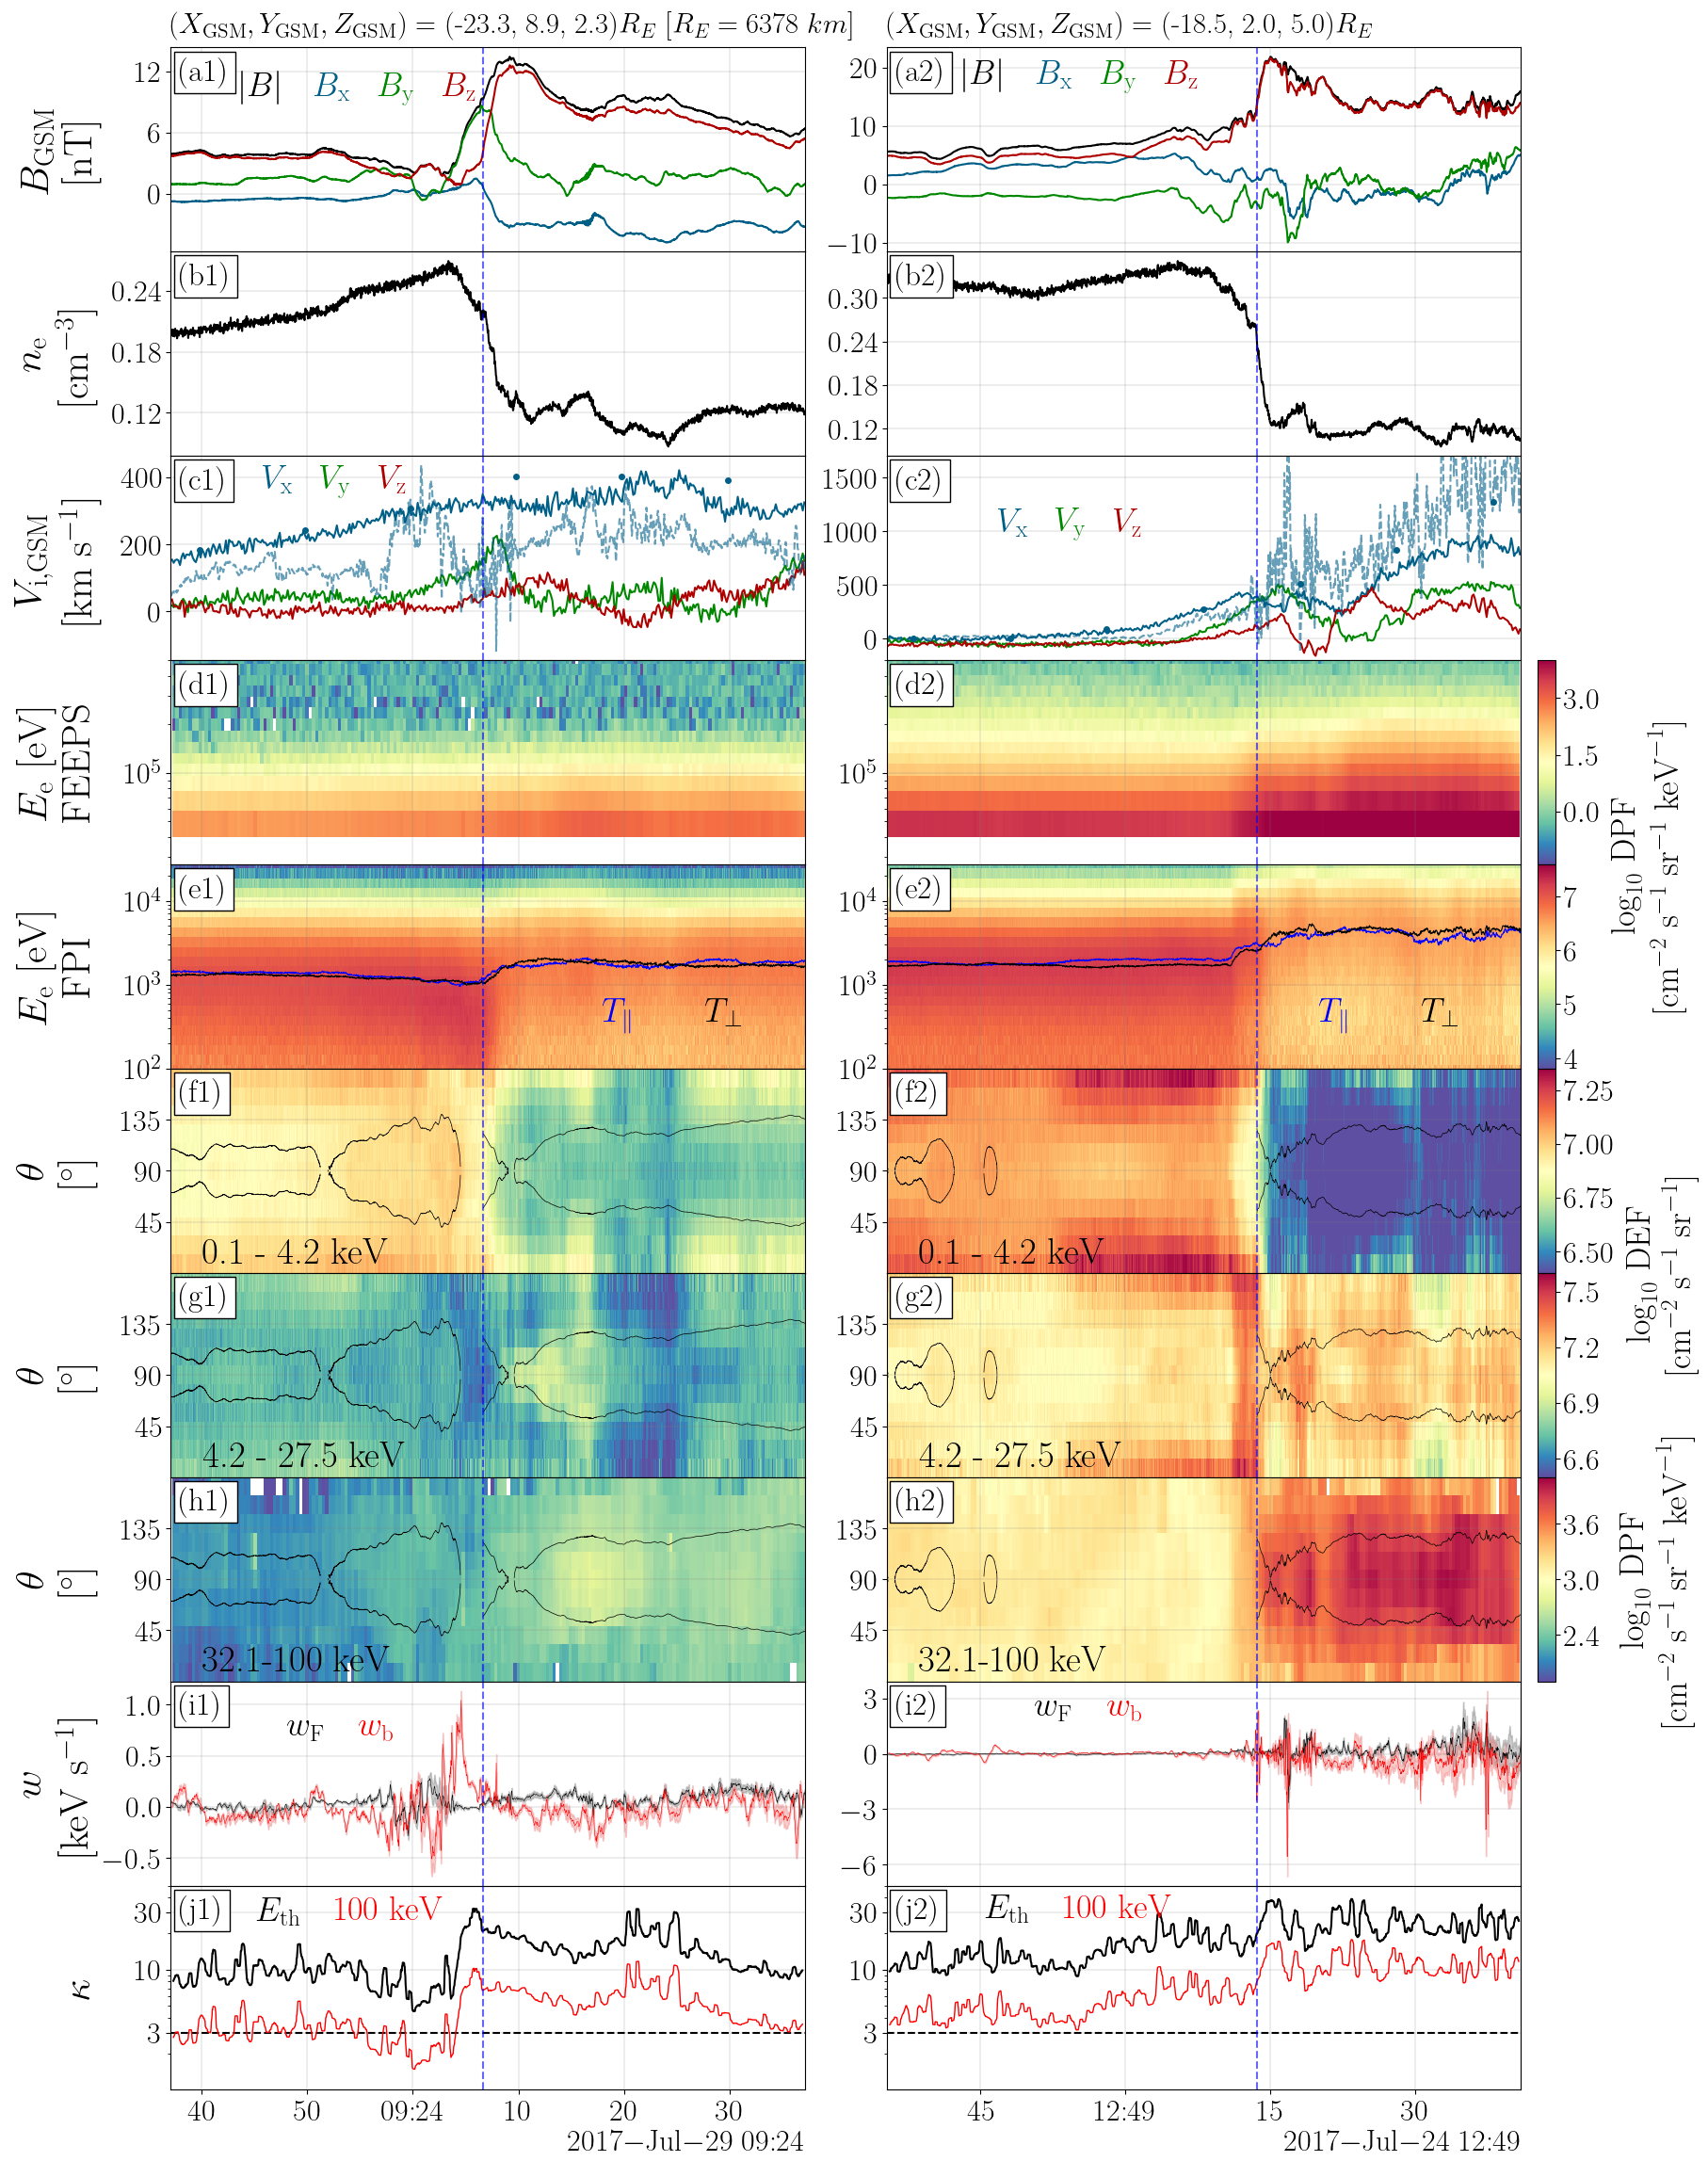

In [ ]:
plot_count = (7 + len(fpi_energy_channels) + len(energy_ranges) + 1)
legend_options = dict(frameon=False, loc="upper right", fontsize = 26, handletextpad = 0.1)
y_label_options = dict(fontsize = 31, )
cb_label_options = dict(fontsize = 26)
caxs_ls = 23
axs_ls = 23
text_fs = 28
cs = 0.7

pad = 8
lw = 0.5
pt = 1./72.27
fig_width = 397.48499 * pt * 3.3
fig_height = 668.4975 * pt * 2.5
f = plt.figure(figsize=(fig_width, fig_height))
gsp1 = f.add_gridspec(
    14, 2, top=0.978, bottom=0.04, left=0.1, right=0.89, hspace=0.0, wspace=0.13
)

gsp10 = gsp1[:, 0].subgridspec(plot_count, 1, hspace=0)
gsp20 = gsp1[:, 1].subgridspec(plot_count, 1, hspace=0)

# Create axes in the grid spec
axs10 = [f.add_subplot(gsp10[i]) for i in range(plot_count)]
[ax.sharex(axs10[0]) for ax in axs10[1:]]
[ax.set_xticks([]) for ax in axs10[:-1]]
axs20 = [f.add_subplot(gsp20[i]) for i in range(plot_count)]
[ax.sharex(axs20[0]) for ax in axs20[1:]]

plot_line(axs10[0], pyrf.time_clip(pyrf.norm(Bgse_avg1), tint = tint1), color = "black", label = "$|B|$")
plot_line(axs10[0], pyrf.time_clip(Bgse_avg1, tint = tint1), label = ["$B_{\mathrm{x}}$", "$B_{\mathrm{y}}$", "$B_{\mathrm{z}}$"])
axs10[0].legend(**legend_options, labelcolor = "linecolor", bbox_to_anchor=(0.53, 1.04), handlelength = 0.0, ncols = 4, columnspacing=cs)
axs10[0].set_ylabel("$B_{\mathrm{GSM}}$ \n [nT]", **y_label_options, labelpad = 1)

plot_line(axs10[1], n_e_avg1, color = "black", label = "$n_{e}$")
axs10[1].set_ylabel("$n_{\mathrm{e}}$ \n [$\mathrm{cm}^{-3}$]", **y_label_options)

plot_line(axs10[2], Vi_avg1, label = ["$V_{\mathrm{x}}$", "$V_{\mathrm{y}}$", "$V_{\mathrm{z}}$"])
plot_line(axs10[2], Vi_avg_hpca1.sel(comp = "x"), marker = "o", linestyle = "none",  color = ('pyrfu:blue'), markersize = 4)
plot_line(axs10[2], u_E_avg1.sel(comp = "x"), color = ('pyrfu:blue'), linestyle = "--", alpha = 0.6)
axs10[2].legend(**legend_options, labelcolor = "linecolor", bbox_to_anchor=(0.42, 1.11), handlelength = 0, ncols = 3, columnspacing=cs)
axs10[2].set_ylabel("$V_{\mathrm{i, GSM}}$ \n [$\mathrm{km}~\mathrm{s^{-1}}$]", **y_label_options, labelpad = 0.7)


axs10[3], caxs3 = plot_spectr(axs10[3], np.log10(dpf_feeps_omni_e_avg1), yscale="log", cmap="Spectral_r", clim = [-1.4, 4])
axs10[3].set_ylabel("$E_{\mathrm{e}}$ [$\mathrm{eV}$]" + "\n" + "FEEPS", **y_label_options)
axs10[3].set_ylim([2.7e4, 0.5e6])

axs10[3].grid(True, which="major", linestyle="-", linewidth="0.2", c="0.5")

axs10[3].set_yscale("log")
caxs3.tick_params(labelsize=caxs_ls)
f.delaxes(caxs3)

axs10[4], caxs4 = plot_spectr(axs10[4], np.log10(dpf_fpi_omni_e_avg1), yscale="log", cmap="Spectral_r", clim = [3.8, 7.6])
plot_line(axs10[4], t_para_e_avg1, label = "$T_{\mathrm{\parallel}}$", color = "blue", linewidth = 0.8)
plot_line(axs10[4], t_perp_e_avg1, label = "$T_{\mathrm{\perp}}$", color = "black", linewidth = 0.8)

axs10[4].legend( **legend_options, bbox_to_anchor=(0.95, 0.5), ncol = 2, labelcolor = "linecolor", handlelength = 0, )
axs10[4].set_ylabel("$E_{\mathrm{e}}$ [$\mathrm{eV}$]" + "\n" + "FPI", **y_label_options)
axs10[4].set_ylim([1e2, 2.7e4])

axs10[4].set_yscale("log")
caxs4.tick_params(labelsize=caxs_ls)
f.delaxes(caxs4)

caxs_fpi_pad = []
clim_fpi_pad = []
clim_fpi = [[6.4, 7.35], [6.5, 7.6]]
for i_fpi in range(0, len(fpi_energy_channels) + 1):
    plot_id = 5 + i_fpi 
    axs10[plot_id], caxs = plot_spectr(axs10[plot_id], np.log10(def_fpi_pad_e_ch_splits_4sc1[i_fpi][0]),  cmap="Spectral_r", clim = clim_fpi[i_fpi])
    clim_fpi_pad.append(caxs.get_ylim())
    axs10[plot_id].set_ylabel("$\\theta$" + "\n" + "[$^\\circ$]", **y_label_options)

    plot_line(axs10[plot_id], th_trs_deg_lower1_b, color = "black", linewidth = lw)
    plot_line(axs10[plot_id], th_trs_deg_upper1_b, color = "black", linewidth = lw)
    plot_line(axs10[plot_id], th_trs_deg_lower1_a, color = "black", linewidth = lw)
    plot_line(axs10[plot_id], th_trs_deg_upper1_a, color = "black", linewidth = lw) 
    caxs.tick_params(labelsize=caxs_ls)
    axs10[plot_id].set_yticks([45, 90, 135])
    axs10[plot_id].set_ylim([0, 180])
    axs10[plot_id].text(0.05, 0.05, def_fpi_pad_e_ch_splits_4sc1[i_fpi][-1], transform=axs10[plot_id].transAxes, fontsize = text_fs, weight = "bold")
    caxs_fpi_pad.append(caxs)
    f.delaxes(caxs)


clim_fpi_pad = [[float(clim_fpi_pad[i][0]), float(clim_fpi_pad[i][1])] for i in range(len(clim_fpi_pad))]

caxs_feeps_pad = []
clim_feeps_pad = []
clim_feeps = [1.9, 4.1]
for i_feeps in range(0, len(energy_ranges) ):

    plot_id = 5 + len(fpi_energy_channels) + i_feeps + 1
    axs10[plot_id], caxs = plot_spectr(axs10[plot_id], np.log10(dpf_feeps_pad_4sc_enranges1[i_feeps]),  cmap="Spectral_r", clim = clim_feeps)
    clim_feeps_pad.append(caxs.get_ylim())
    axs10[plot_id].set_ylabel("$\\theta$" + "\n" + "[$^\\circ$]", **y_label_options)

    plot_line(axs10[plot_id], th_trs_deg_lower1_b, color = "black", linewidth = lw)
    plot_line(axs10[plot_id], th_trs_deg_upper1_b, color = "black", linewidth = lw)
    plot_line(axs10[plot_id], th_trs_deg_lower1_a, color = "black", linewidth = lw)
    plot_line(axs10[plot_id], th_trs_deg_upper1_a, color = "black", linewidth = lw)

    caxs.tick_params(labelsize=caxs_ls)
    axs10[plot_id].set_yticks([45, 90, 135])
    axs10[plot_id].set_ylim([0, 180])
    axs10[plot_id].text(0.05, 0.05, f"{energy_ranges[i_feeps][0]}-{energy_ranges[i_feeps][1]} keV", transform=axs10[plot_id].transAxes, fontsize = text_fs, weight = "bold")
    caxs_feeps_pad.append(caxs)
    f.delaxes(caxs)

clim_feeps_pad = [[float(clim_feeps_pad[i][0]), float(clim_feeps_pad[i][1])] for i in range(len(clim_feeps_pad))]

plot_id = 5 + len(fpi_energy_channels) + len(energy_ranges)

axs10[plot_id + 1].fill_between(dw_fermi1.time.data, w_fermi1.data - np.abs(dw_fermi1.data), w_fermi1.data + np.abs(dw_fermi1.data), color = "gray", alpha = 0.4,)
axs10[plot_id + 1].fill_between(dw_betatron1.time.data, w_betatron1.data - np.abs(dw_betatron1.data), w_betatron1.data + np.abs(dw_betatron1.data), color = "lightcoral", alpha = 0.4,)

plot_line(axs10[plot_id + 1], w_fermi1, color = "black", linestyle ="-", label = "$w_{\mathrm{F}}$", alpha = 1, lw = 0.4)# {n_pts}-pt moving average")
plot_line(axs10[plot_id + 1], w_betatron1, color = "red",linestyle ="-", label = "$w_{\mathrm{b}}$", alpha = 1, lw = 0.4)


axs10[plot_id + 1].legend( **legend_options, bbox_to_anchor=(0.4, 1), labelcolor = "linecolor", handlelength =0, ncols = 2, columnspacing=0.9)
axs10[plot_id + 1].set_ylabel("$w$"+"\n"+ "$[\mathrm{keV}~\mathrm{s^{-1}}]$", **y_label_options)
plot_line(axs10[plot_id + 2], kappa_roll1, label = "$E_{\mathrm{th}}$", color = "black")

hline_kappa_limit = axs10[plot_id + 2].axhline(y = 3, color = "black", linestyle = "--")

plot_line(axs10[plot_id + 2], kappa_extra_energy1, label = "$100~\mathrm{keV}$", linewidth = 1, color = "red")
axs10[plot_id + 2].set_yscale("log")

axs10[plot_id + 2].set_ylabel("$\kappa$", **y_label_options)
axs10[plot_id + 2].legend(**legend_options, bbox_to_anchor=(0.48, 1.1), labelcolor = "linecolor", handlelength = 0, ncols = 2, columnspacing=0.9)
axs10[plot_id + 2].set_yticks([3e0, 1e1, 3e1], minor = False)
axs10[plot_id + 2].get_yaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
axs10[plot_id + 2].set_ylim([1, 50])

vline_max_slope = [ax.axvline(x = pyrf.iso86012datetime64(t_max_slope1.data), color = "blue", linestyle = "--", alpha = 0.6) for ax in axs10]

axs10[0].annotate(text = "$(X_{\mathrm{GSM}}, Y_{\mathrm{GSM}}, Z_{\mathrm{GSM}}) = ($" + f"{r_mean01}, {r_mean11}, {r_mean21}" + "$) R_{E}$ [$R_{E} = 6378~km$]", 
                xy = (0 , 1.07), xycoords = 'axes fraction', color = "black", fontsize = 22)

make_labels(axs10, [0.013, 0.84], bbox=dict(facecolor='white', edgecolor='black',), num = "1", fontsize = 24)
[ax.tick_params(labelsize=axs_ls) for ax in axs10]
axs10[-1].xaxis.get_offset_text().set_size(axs_ls)

[ax.set_xlim(pyrf.iso86012datetime64(tint1)) for ax in axs10]
f.align_ylabels(axs10)

## -------------------------------------------------------------------------------------------------------------------
## ## Plotting the second part of the figure    

plot_line(axs20[0], pyrf.norm(Bgse_avg2), color = "black", label = "$|B|$")
plot_line(axs20[0], Bgse_avg2, label = ["$B_{\mathrm{x}}$", "$B_{\mathrm{y}}$", "$B_{\mathrm{z}}$"])
axs20[0].legend(**legend_options, labelcolor = "linecolor", bbox_to_anchor=(0.54, 1.1), handlelength = 0, ncols = 4, columnspacing=cs)

plot_line(axs20[1], n_e_avg2, color = "black", label = "$n_{e}$")
axs20[1].set_yticks([0.12, 0.18, 0.24, 0.30])

plot_line(axs20[2], Vi_avg2, label = ["$V_{\mathrm{x}}$", "$V_{\mathrm{y}}$", "$V_{\mathrm{z}}$"])
plot_line(axs20[2], Vi_avg_hpca2.sel(comp = "x"), marker = "o", linestyle = "none",  color = ('pyrfu:blue'), markersize = 4)
plot_line(axs20[2], u_E_avg2.sel(comp = "x"), color = ('pyrfu:blue'), linestyle = "--", alpha = 0.6)

axs20[2].set_ylim([-200, 1700])

axs20[2].legend(**legend_options, labelcolor = "linecolor", bbox_to_anchor=(0.45, 0.9), handlelength = 0, ncols = 3, columnspacing=cs)

axs20[3], caxs3 = plot_spectr(axs20[3], np.log10(dpf_feeps_omni_e_avg2), yscale="log", cmap="Spectral_r", clim = [-1.4, 4])
axs20[3].grid(True, which="major", linestyle="-", linewidth="0.2", c="0.5")
axs20[3].set_ylim([2.7e4, 0.5e6])

axs20[3].set_yscale("log")
caxs3.tick_params(labelsize=caxs_ls)

axs20[4], caxs4 = plot_spectr(axs20[4], np.log10(dpf_fpi_omni_e_avg2), yscale="log", cmap="Spectral_r", clim = [3.8, 7.6])
plot_line(axs20[4], t_para_e_avg2, label = "$T_{\mathrm{\parallel}}$", color = "blue", linewidth = 0.8)
plot_line(axs20[4], t_perp_e_avg2, label = "$T_{\mathrm{\perp}}$", color = "black", linewidth = 0.8)

axs20[4].legend( **legend_options, bbox_to_anchor=(0.95, 0.5), ncol = 2, labelcolor = "linecolor", handlelength = 0,)
axs20[4].set_ylim([1e2, 2.7e4])

axs20[4].set_yscale("log")
caxs4.set_ylabel("$\log_{10}$ DPF \n $[\mathrm{cm}^{-2} ~\mathrm{s}^{-1} ~\mathrm{sr}^{-1} ~\mathrm{keV}^{-1}]$", **cb_label_options, y = 1, labelpad = 25)
caxs4.tick_params(labelsize=caxs_ls)

caxs_fpi_pad = []

for i_fpi in range(0, len(fpi_energy_channels) + 1):
    plot_id = 5 + i_fpi 
    axs20[plot_id], caxs = plot_spectr(axs20[plot_id], np.log10(def_fpi_pad_e_ch_splits_4sc2[i_fpi][0]),  cmap="Spectral_r", clim= clim_fpi[i_fpi])
    if i_fpi == 0 and (len(fpi_energy_channels) + 1) % 2 == 1:
        caxs.set_ylabel("$\log_{10}$ DEF \n $[\\mathrm{cm}^{-2}~\\mathrm{s}^{-1}~\\mathrm{sr}^{-1}]$", **cb_label_options, x = 1, y = 0.5, labelpad = 20
        )
    elif i_fpi == 1 and (len(fpi_energy_channels) + 1) % 2 == 0:
        caxs.set_ylabel("$\log_{10}$ DEF \n $[\\mathrm{cm}^{-2}~\\mathrm{s}^{-1}~\\mathrm{sr}^{-1}]$", **cb_label_options, x= 1, y = 1, labelpad = 20
        )

    plot_line(axs20[plot_id], th_trs_deg_lower2_b, color = "black", linewidth = lw)
    plot_line(axs20[plot_id], th_trs_deg_upper2_b, color = "black", linewidth = lw)
    plot_line(axs20[plot_id], th_trs_deg_lower2_a, color = "black", linewidth = lw)
    plot_line(axs20[plot_id], th_trs_deg_upper2_a, color = "black", linewidth = lw)

    caxs.tick_params(labelsize=caxs_ls)
    axs20[plot_id].set_yticks([45, 90, 135])
    axs20[plot_id].set_ylim([0, 180])
    axs20[plot_id].text(0.05, 0.05, def_fpi_pad_e_ch_splits_4sc2[i_fpi][-1], transform=axs20[plot_id].transAxes, fontsize = text_fs, weight = "bold")
    caxs_fpi_pad.append(caxs)
    

caxs_feeps_pad = []

for i_feeps in range(0, len(energy_ranges)):
    
    plot_id = 5 + len(fpi_energy_channels) + i_feeps +1
    axs20[plot_id], caxs = plot_spectr(axs20[plot_id], np.log10(dpf_feeps_pad_4sc_enranges2[i_feeps]),  cmap="Spectral_r", clim = clim_feeps)

    if i_feeps == 0 and (len(energy_ranges)  ) % 2 == 1:
        caxs.set_ylabel("$\log_{10}$ DPF \n $[\mathrm{cm}^{-2} ~\mathrm{s}^{-1} ~\mathrm{sr}^{-1} ~\mathrm{keV}^{-1}]$", **cb_label_options, x = 1, y = 0.5, labelpad = 15
        )
    elif i_feeps == 1 and (len(energy_ranges) + 1) % 2 == 0:
        caxs.set_ylabel("$\log_{10}$ DPF \n $[\mathrm{cm}^{-2} ~\mathrm{s}^{-1} ~\mathrm{sr}^{-1} ~\mathrm{keV}^{-1}]$", **cb_label_options, x= 1, y = 1, labelpad = 15
        )

    plot_line(axs20[plot_id], th_trs_deg_lower2_b, color = "black", linewidth = lw)
    plot_line(axs20[plot_id], th_trs_deg_upper2_b, color = "black", linewidth = lw)
    plot_line(axs20[plot_id], th_trs_deg_lower2_a, color = "black", linewidth = lw)
    plot_line(axs20[plot_id], th_trs_deg_upper2_a, color = "black", linewidth = lw)

    caxs.tick_params(labelsize=caxs_ls)
    axs20[plot_id].set_yticks([45, 90, 135])
    axs20[plot_id].set_ylim([0, 180])
    axs20[plot_id].text(0.05, 0.05, f"{energy_ranges[i_feeps][0]}-{energy_ranges[i_feeps][1]} keV", transform=axs20[plot_id].transAxes, fontsize = text_fs, weight = "bold")
    caxs_feeps_pad.append(caxs)


plot_id = 5 + len(fpi_energy_channels) + len(energy_ranges)

axs20[plot_id + 1].fill_between(dw_fermi2.time.data, w_fermi2.data - np.abs(dw_fermi2.data), w_fermi2.data + np.abs(dw_fermi2.data), color = "gray", alpha = 0.4,)
axs20[plot_id + 1].fill_between(dw_betatron2.time.data, w_betatron2.data - np.abs(dw_betatron2.data), w_betatron2.data + np.abs(dw_betatron2.data), color = "lightcoral", alpha = 0.4,)

plot_line(axs20[plot_id + 1], w_fermi2, color = "black", linestyle ="-", label = "$w_{\mathrm{F}}$", alpha = 1, lw = 0.4)# {n_pts}-pt moving average")
plot_line(axs20[plot_id + 1], w_betatron2, color = "red",linestyle ="-", label = "$w_{\mathrm{b}}$", alpha = 1, lw = 0.4)

axs20[plot_id + 1].legend( **legend_options, bbox_to_anchor=(0.45, 1.1), labelcolor = "linecolor", handlelength =0, ncols = 2, columnspacing=0.9)
        
plot_line(axs20[plot_id + 2], kappa_roll2, label = "$E_{\mathrm{th}}$", color = "black")

hline_kappa_limit = axs20[plot_id + 2].axhline(y = 3, color = "black", linestyle = "--")

plot_line(axs20[plot_id + 2], kappa_extra_energy2, label = "$100~\mathrm{keV}$", linewidth = 1, color = "red")
axs20[plot_id + 2].set_yscale("log")

axs20[plot_id + 2].legend(**legend_options, bbox_to_anchor=(0.5, 1.11), labelcolor = "linecolor", handlelength = 0, ncols = 2, columnspacing=0.9)
axs20[plot_id + 2].set_yticks([3e0, 1e1, 3e1], minor = False)
axs20[plot_id + 2].get_yaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
axs20[plot_id + 2].set_ylim([1, 50])

vline_max_slope = [ax.axvline(x = pyrf.iso86012datetime64(t_max_slope2.data), color = "blue", linestyle = "--", alpha = 0.6) for ax in axs20]

axs20[0].annotate(text = "$(X_{\mathrm{GSM}}, Y_{\mathrm{GSM}}, Z_{\mathrm{GSM}}) = ($" + f"{r_mean02}, {r_mean12}, {r_mean22}" + "$) R_{E}$", 
                xy = (0 , 1.07), xycoords = 'axes fraction', color = "black", fontsize = 22)

make_labels(axs20, [0.013, 0.84], bbox=dict(facecolor='white', edgecolor='black',), num = "2", fontsize = 24)

[ax.tick_params(labelsize=axs_ls) for ax in axs20]
axs20[-1].xaxis.get_offset_text().set_size(axs_ls)

f.align_ylabels(axs20)
# f.savefig(f"paper_figs/figure_1_v4_er.png", dpi = 500, bbox_inches='tight', )